# Demanda de Inventario de Grupo Bimbo

## 1. Tiempo y logística

* **`Semana` (Número de semana):** Representa el período de tiempo de la transacción. La semana operativa de Grupo Bimbo comprende desde el jueves hasta el miércoles.
* **`Agencia_ID` (Identificador de agencia):** Identifica el centro de distribución físico donde se cargan los camiones de reparto con productos frescos.
* **`Canal_ID` (Identificador de canal de ventas):** Identifica la categoría del cliente, como pequeñas tiendas de barrio (*tienditas*), grandes supermercados y tiendas de conveniencia.
* **`Ruta_SAK` (Identificador de ruta):** Identifica la ruta geográfica específica que recorre un camión de reparto. Una misma agencia puede tener varias rutas de distribución.

## 2. Entidades

* **`Cliente_ID` y `NombreCliente` (Identificador y nombre del cliente):** Identifican la tienda específica que recibe la entrega, como «Abarrotes La Lupita» o una sucursal de Walmart.
* **`Producto_ID` y `NombreProducto` (Identificador y nombre del producto):** Identifican el producto específico que se entrega, incluyendo su marca, nombre y peso. Por ejemplo, «Pan Blanco Bimbo 680 g».

## 3. Flujo de transacciones

* **`Venta_uni_hoy` (Unidades entregadas esta semana):** Número de unidades de producto que el conductor entrega físicamente a la tienda durante la semana actual.
* **`Venta_hoy` (Ingresos por ventas de esta semana):** Ingresos brutos, expresados en pesos mexicanos, correspondientes a las unidades entregadas a la tienda.
* **`Dev_uni_proxima` (Unidades devueltas la próxima semana):** Número de unidades de la entrega actual que no se vendieron antes de caducar. El conductor recoge estos productos vencidos, conocidos como *merma por caducidad*, durante la entrega de la semana siguiente.
* **`Dev_proxima` (Valor de las devoluciones de la próxima semana):** Valor monetario, expresado en pesos mexicanos, reembolsado o acreditado a la tienda por las unidades devueltas debido a su caducidad.

## 4. Variable objetivo: `Demanda_uni_equil`

La **demanda ajustada** es la variable objetivo que se busca predecir. Representa una estimación de la demanda del consumidor final: la cantidad de unidades de producto que los consumidores realmente compraron, en lugar de limitarse a contar las unidades entregadas a una tienda.

La variable objetivo se calcula mediante la siguiente fórmula:

$$
\text{Demanda\_uni\_equil} =
\max(0,\ \text{Venta\_uni\_hoy} - \text{Dev\_uni\_proxima})
$$

Donde:

* `Venta_uni_hoy`: Unidades entregadas durante la semana actual.
* `Dev_uni_proxima`: Unidades de esa entrega que se devuelven durante la semana siguiente.
* `max(0, ...)`: Garantiza que la demanda ajustada no sea negativa.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
print(os.getcwd())

C:\Users\alexi\OneDrive\Escritorio\Personal\Proyecto_DL\backend\ai


In [22]:
dtypes = {
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}
df = pd.read_csv("../data/raw/train.csv", dtype=dtypes, skiprows=range(1, 50_000_001), nrows=3_000_000) #nrows=3_000_000) #May change
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,7,2013,1,1231,754890,41843,10,68.599998,0,0.0,10
1,7,2013,1,1231,754890,41938,2,19.820000,0,0.0,2
2,7,2013,1,1231,861224,1125,2,19.200001,0,0.0,2
3,7,2013,1,1231,861224,1212,1,8.380000,0,0.0,1
4,7,2013,1,1231,861224,1240,4,33.520000,0,0.0,4


In [24]:
#df.to_csv("train_sample_2.csv", index= False)

In [4]:
print('cantidad de observaciones (clientes): ',df.shape[0])
print('cantidad de variables: ',df.shape[1])
print(df.shape)

cantidad de observaciones (clientes):  3000000
cantidad de variables:  11
(3000000, 11)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000000 entries, 0 to 2999999
Data columns (total 11 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Semana             int8   
 1   Agencia_ID         int16  
 2   Canal_ID           int8   
 3   Ruta_SAK           int32  
 4   Cliente_ID         int32  
 5   Producto_ID        int32  
 6   Venta_uni_hoy      int32  
 7   Venta_hoy          float32
 8   Dev_uni_proxima    int32  
 9   Dev_proxima        float32
 10  Demanda_uni_equil  int32  
dtypes: float32(2), int16(1), int32(6), int8(2)
memory usage: 103.0 MB


In [6]:
df.describe()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
count,3000000.0,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06,3.000000e+06
mean,3.0,1.187730e+03,1.277710e+00,1.921721e+03,1.551280e+06,1.689541e+04,6.900179e+00,6.662614e+01,1.031367e-01,1.052810e+00,6.829191e+00
std,0.0,6.405810e+01,1.156798e+00,1.247875e+03,1.659155e+06,1.803580e+04,2.242889e+01,4.234580e+02,2.169038e+00,1.989941e+01,2.217677e+01
min,3.0,1.110000e+03,1.000000e+00,1.000000e+00,7.720000e+02,7.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.0,1.123000e+03,1.000000e+00,1.204000e+03,3.000770e+05,1.232000e+03,2.000000e+00,1.796000e+01,0.000000e+00,0.000000e+00,2.000000e+00
50%,3.0,1.212000e+03,1.000000e+00,1.425000e+03,9.880360e+05,3.270000e+03,3.000000e+00,3.125000e+01,0.000000e+00,0.000000e+00,3.000000e+00
75%,3.0,1.232000e+03,1.000000e+00,2.112000e+03,2.195924e+06,3.545200e+04,6.000000e+00,5.918000e+01,0.000000e+00,0.000000e+00,6.000000e+00
max,3.0,1.315000e+03,1.100000e+01,9.709000e+03,1.000000e+08,4.999400e+04,4.800000e+03,3.826944e+05,2.400000e+03,1.521960e+04,4.800000e+03


In [7]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [8]:
###
###
for colu in df.columns:
    cantidad = df[colu].value_counts()
    #print(f"Nombre de Columna {colu}: Tiene {cantidad} valores.\n----")
    print(f"{cantidad} \n-------" )

Semana
3    3000000
Name: count, dtype: int64 
-------
Agencia_ID
1123    111015
1220    102694
1219     93925
1126     87708
1312     85495
         ...  
1250       642
1167       551
1229       498
1273       294
1160         4
Name: count, Length: 87, dtype: int64 
-------
Canal_ID
1     2796131
4       79328
7       56990
2       28826
6       20665
5        7840
11       6052
8        4168
Name: count, dtype: int64 
-------
Ruta_SAK
1201    18194
1203    15461
1213    14374
1202    13880
1601    13837
        ...  
7357        1
7359        1
7361        1
7365        1
7373        1
Name: count, Length: 1315, dtype: int64 
-------
Cliente_ID
653378     6568
653039      790
625491      187
1404831     129
19260       125
           ... 
2469868       1
2469518       1
4602802       1
2219003       1
4435826       1
Name: count, Length: 179020, dtype: int64 
-------
Producto_ID
1250     91195
1240     90615
1242     86989
1278     83125
2233     78331
         ...  
35572        1

In [20]:
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID' 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#varCatOrdinal = []

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

In [10]:
df.columns

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')

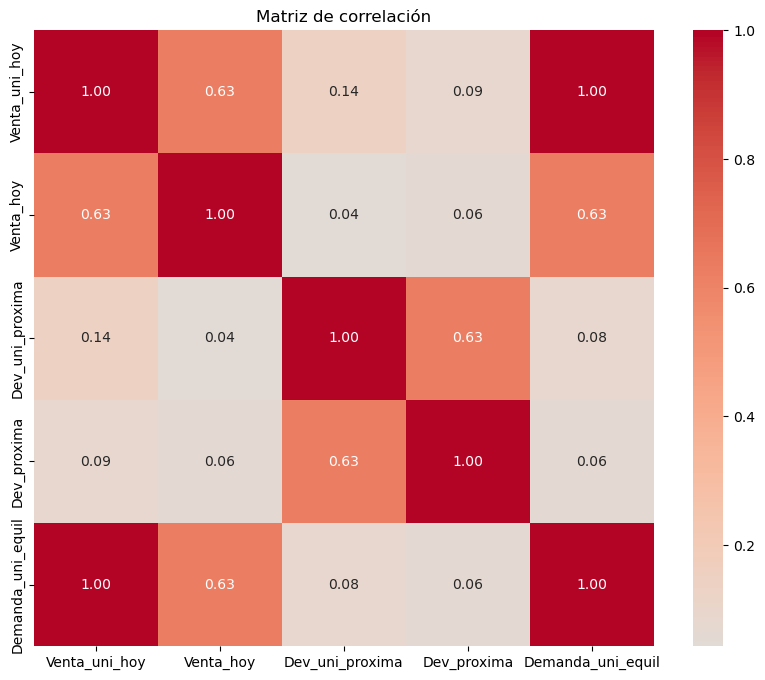

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()